# Training examples

Turn `sequences.csv` into the examples the next-hold model learns from. One example = one grab: the climber's state just before the move (which holds each hand is on, which holds were already used), the route's candidate holds, and the answer (the hold grabbed next and the hand that grabbed it).

| Feature | Meaning |
|---|---|
| `dx_L`, `dy_L` | Hold center minus left hand position. `dx` + = right of the hand, `dy` + = **above** the hand |
| `dx_R`, `dy_R` | Same for the right hand |
| `width`, `height` | Hold size |
| `held_L`, `held_R` | 1 if that hand is on this hold now |
| `is_start`, `is_end` | Route's start / end hold |
| `is_volume` | Volume |
| `used` | 1 if either hand has already touched this hold in this climb |

## Cell 1: Setup

Settings:
- `N_JITTER`: jitter copies per grab. We use 3 for data augmentation.
- `JITTER_GAP_S`: minimum time between two jitter copies of the same grab, so they aren't exact dupes.
- `JITTER_END_MARGIN_S`: jitter copies stop this long before the moving hand lets go to avoid problems.
- `CONF_MIN`: jitter copies only use hand points the pose model was confident about.
- `INCLUDE_VOLUMES`: volumes always candidates on a route.

In [ ]:
import os, re, json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/ECS-174-Project'
MAP_DIR = f'{BASE}/hold-maps'
POSE_DIR = f'{BASE}/annotated-csv'
SEQ_PATH = f'{BASE}/sequences.csv'
EMB_PATH = f'{BASE}/embeddings/hold_embeddings.npz'
FPS_CACHE = f'{BASE}/contact-checks/video_fps.csv'
OUT_DIR = f'{BASE}/examples'
os.makedirs(f'{OUT_DIR}/checks', exist_ok=True)

# excluded positions cuz couldn't get solid hold map
EXCLUDE_POSITIONS = {'pos2', 'pos4', 'pos6', 'pos7', 'pos11', 'pos18', 'pos22', 'pos25'}
EXCLUDE_VIDEOS = {'ronish-blue-14'}

N_JITTER = 3
JITTER_GAP_S = 0.3
JITTER_END_MARGIN_S = 0.2
CONF_MIN = 0.5
INCLUDE_VOLUMES = True

FEATURES = ['dx_L', 'dy_L', 'dx_R', 'dy_R', 'width', 'height',
            'held_L', 'held_R', 'is_start', 'is_end', 'is_volume', 'used']

Mounted at /content/drive


## Cell 2: Load sequences, metadata, holds and routes

Reads `sequences.csv` and the files that describe each route.

In [ ]:
def video_name(v):
    return re.sub(r'\.(mp4|mov|m4v|avi)$', '', str(v).strip(), flags=re.IGNORECASE)

def normalize_pos(s):
    m = re.search(r'pos0*(\d+)', str(s).lower())
    return f'pos{m.group(1)}' if m else None

def norm_route(r):
    return re.sub(r'[^a-z0-9]', '', str(r).lower())

seq = pd.read_csv(SEQ_PATH)
seq['key'] = seq['video'].map(video_name).str.lower()
seq['route_id'] = seq['route_id'].map(norm_route)
seq['position_id'] = seq['position_id'].map(normalize_pos)
seq = seq[~seq.position_id.isin(EXCLUDE_POSITIONS) & ~seq.key.isin(EXCLUDE_VIDEOS)]
seq = seq.sort_values(['video', 'order']).reset_index(drop=True)

meta = pd.read_csv(f'{BASE}/metadata.csv')
meta = meta[meta['Filename'].notna()].copy()
meta['key'] = meta['Filename'].map(video_name).str.lower()
meta = meta.drop_duplicates('key').set_index('key')
FALL_WORDS = ('fall', 'fell', 'flop', 'drop', 'fail')
fell = meta['Outcome'].astype(str).str.lower().str.contains('|'.join(FALL_WORDS)).to_dict()

holds = pd.read_csv(f'{MAP_DIR}/holds.csv')
holds['position_id'] = holds['position_id'].map(normalize_pos)
holds['hold_id'] = holds['hold_id'].astype(int)
holds['cls'] = holds['cls'].astype(str).str.lower()
hw = holds[holds.cls == 'hold'].groupby('position_id')['width'].median()
hold_width = holds.groupby('position_id')['width'].median()
hold_width.update(hw)

routes = pd.read_csv(f'{MAP_DIR}/routes.csv')
routes = routes.loc[:, ~routes.columns.astype(str).str.startswith('Unnamed')]
routes['position_id'] = routes['position_id'].map(normalize_pos)
routes['route_id'] = routes['route_id'].map(norm_route)
routes['hold_id'] = routes['hold_id'].astype(int)
routes['on_route'] = pd.to_numeric(routes['on_route'], errors='coerce').fillna(0).astype(int)
routes['role'] = routes['role'].fillna('').astype(str).str.strip().str.lower()

n_ex = (seq.kind != 'start').sum()
print(f'{len(seq)} contacts in {seq.video.nunique()} videos, {seq.route_id.nunique()} routes; '
      f'{n_ex} grabs and matches (one example each)')
print('Kinds:', seq.kind.value_counts().to_dict(), '| falls:', sum(fell.get(k, False) for k in seq.key.unique()), 'videos')

1460 contacts in 128 videos, 68 routes; 1216 grabs and matches (one example each)
Kinds: {'grab': 1003, 'start': 244, 'match': 213} | falls: 14 videos


## Cell 3: Candidate holds per route, with embedding rows

Build the list of candidate holds in a fixed order. For each candidate it records center, size, start/end/volume flags, and its row in `hold_embeddings.npz`, so training can look up the appearance embedding.

`K_MAX` is the largest number of candidates on any route. Every example's token list is padded to `K_MAX` rows, and a mask marks which rows are real holds and which are padding, so model ignores the padding.

In [ ]:
emb = np.load(EMB_PATH)
emb_row = {(normalize_pos(p), int(h)): i for i, (p, h) in enumerate(zip(emb['position_id'], emb['hold_id']))}
print(f'Embeddings: {len(emb_row)} holds, arrays', {k: emb[k].shape for k in ('hold', 'cls')})

hinfo = holds.set_index(['position_id', 'hold_id'])
candidates, problems = {}, []
for (r, p), _ in seq.groupby(['route_id', 'position_id']):
    rr = routes[(routes.route_id == r) & (routes.position_id == p) & (routes.on_route == 1)]
    ids = set(rr.hold_id)
    if INCLUDE_VOLUMES:
        ids |= set(holds[(holds.position_id == p) & (holds.cls == 'volume')].hold_id)
    role = rr.groupby('hold_id')['role'].first()
    rows = []
    for h in sorted(ids):
        if (p, h) not in hinfo.index:
            problems.append(f'{r} {p}: hold {h} not in holds.csv'); continue
        i = hinfo.loc[(p, h)]
        e = emb_row.get((p, h), -1)
        if e < 0:
            problems.append(f'{r} {p}: hold {h} has no embedding')
        rl = role.get(h, '')
        rows.append({'route_id': r, 'position_id': p, 'hold_id': h, 'cx': i.center_x, 'cy': i.center_y,
                     'w': i.width, 'h': i.height, 'is_start': int('start' in rl),
                     'is_end': int(rl in ('end', 'finish') or 'finish' in rl),
                     'is_volume': int(i.cls == 'volume'), 'emb_row': e})
    candidates[(r, p)] = pd.DataFrame(rows)

cand_all = pd.concat(candidates.values(), ignore_index=True)
K_MAX = int(cand_all.groupby(['route_id', 'position_id']).size().max())
bad = seq[[h not in set(candidates[(r, p)].hold_id) for r, p, h in zip(seq.route_id, seq.position_id, seq.hold_id)]]
print(f'{len(candidates)} route/position pairs; candidates per route: median '
      f'{cand_all.groupby(["route_id", "position_id"]).size().median():.0f}, K_MAX {K_MAX}')
print(f'{sum("embedding" in m for m in problems)} candidates without an embedding; '
      f'{len(bad)} contacts on holds that aren\'t candidates')
for m in problems[:20]:
    print('  PROBLEM', m)

Embeddings: 4309 holds, arrays {'hold': (4309, 5, 384), 'cls': (4309, 5, 384)}
69 route/position pairs; candidates per route: median 20, K_MAX 32
0 candidates without an embedding; 0 contacts on holds that aren't candidates


## Cell 4: Load hand tracks

Jitter copies need the real hand positions in the frames before each move, so this reloads the pose CSVs the same way contact extraction does.

In [ ]:
fps_of = pd.read_csv(FPS_CACHE).dropna(subset=['fps']).set_index('key')['fps'].to_dict()
align = pd.read_csv(f'{BASE}/hold-maps/video_alignment.csv')
vcol = next(c for c in align.columns if c.lower() in ('video', 'filename', 'name', 'video_name'))
align['key'] = align[vcol].map(video_name).str.lower()
MCOLS = ['m00', 'm01', 'm02', 'm10', 'm11', 'm12']
affine = {}
for _, a in align.iterrows():
    m = pd.to_numeric(a[MCOLS], errors='coerce').to_numpy(float)
    affine[a['key']] = None if np.isnan(m).any() else m.reshape(2, 3)

pose_files = {}
for f in sorted(os.listdir(POSE_DIR)):
    m = re.match(r'(.+?)(_hands)?\.csv$', f, flags=re.IGNORECASE)
    if m:
        k = video_name(m.group(1)).lower()
        if m.group(2) or k not in pose_files:
            pose_files[k] = os.path.join(POSE_DIR, f)

tracks, missing = {}, []
for k in seq.key.unique():
    if k not in pose_files or k not in fps_of:
        missing.append(k); continue
    df = pd.read_csv(pose_files[k]).sort_values('frame')
    t = df['frame'].to_numpy(float) / fps_of[k]
    found = df['person_found'].fillna(0).astype(float).to_numpy() > 0
    M = affine.get(k)
    tr = {'t': t}
    for hand, px in (('L', 'l'), ('R', 'r')):
        x = df[f'{px}hand_x'].to_numpy(float)
        y = df[f'{px}hand_y'].to_numpy(float)
        bad = ~found | (df[f'{px}wrist_conf'].fillna(0).to_numpy(float) < CONF_MIN)
        x, y = np.where(bad, np.nan, x), np.where(bad, np.nan, y)
        if M is not None:
            x, y = M[0, 0] * x + M[0, 1] * y + M[0, 2], M[1, 0] * x + M[1, 1] * y + M[1, 2]
        tr[hand] = (x, y)
    tracks[k] = tr
print(f'{len(tracks)} videos with tracks; {len(missing)} missing:', missing)

128 videos with tracks; 0 missing: []


## Cell 5: Replay every climb into examples

Walks through each video's contacts in order, keeping the state: which hold each hand is on, since when, and which holds have been used.
- A `start` contact only updates the state.
- A `grab` or `match` first saves an example (the state just before it, plus the answer: this hold, this hand), then updates the state.

Hand positions in a clean example are the centers of the holds the hands are on. A hand not yet on any hold uses its last seen position.

In [ ]:
def last_seen(tr, hand, t):
    """Most recent visible position of a hand at or before time t, or None."""
    x, y = tr[hand]
    ok = (tr['t'] <= t + 1e-6) & ~np.isnan(x)
    if not ok.any():
        return None
    i = np.flatnonzero(ok)[-1]
    return float(x[i]), float(y[i])

def jitter_times(tr, held, w0, w1):
    """Sample times in [w0, w1] where every hand in `held` was seen, spread out, at most N_JITTER."""
    t = tr['t']
    ok = (t >= w0) & (t <= w1)
    for h in held:
        ok &= ~np.isnan(tr[h][0])
    idx = np.flatnonzero(ok)
    if len(idx) == 0 or N_JITTER == 0:
        return []
    pick = idx[np.unique(np.linspace(0, len(idx) - 1, min(N_JITTER * 3, len(idx))).round().astype(int))]
    out = []
    for i in pick[::-1]:                     # prefer moments closest to the move
        if all(abs(t[i] - t[j]) >= JITTER_GAP_S for j in out):
            out.append(i)
        if len(out) == N_JITTER:
            break
    return sorted(out)

rows, skipped = [], 0
for video, s in seq.groupby('video', sort=False):
    k = s.key.iloc[0]
    r_id, p_id = s.route_id.iloc[0], s.position_id.iloc[0]
    cands = candidates[(r_id, p_id)]
    center = dict(zip(cands.hold_id, zip(cands.cx, cands.cy)))
    tr = tracks.get(k)
    hold = {'L': None, 'R': None}
    since = {'L': None, 'R': None}
    until = {'L': None, 'R': None}
    used = set()
    step = 0
    for c in s.itertuples():
        if c.kind != 'start':
            pos = {}
            for h in 'LR':
                if hold[h] is not None:
                    pos[h] = center[hold[h]]
                else:
                    pos[h] = last_seen(tr, h, c.time_s) if tr is not None else None
            if pos['L'] is None and pos['R'] is None:
                skipped += 1
            else:
                pos['L'] = pos['L'] or pos['R']
                pos['R'] = pos['R'] or pos['L']
                base = {'video': video, 'key': k, 'route_id': r_id, 'position_id': p_id, 'step': step,
                        'kind': c.kind, 'inferred': int(getattr(c, 'inferred', 0) or 0),
                        'fell': int(fell.get(k, False)), 'target_hold': int(c.hold_id), 'hand': c.hand,
                        'L_hold': hold['L'] if hold['L'] is not None else -1,
                        'R_hold': hold['R'] if hold['R'] is not None else -1,
                        'used': ';'.join(str(u) for u in sorted(used))}
                ex_id = len(rows)
                rows.append({**base, 'example_id': ex_id, 'is_jitter': 0, 'source': ex_id, 'time_s': c.time_s,
                             'L_x': pos['L'][0], 'L_y': pos['L'][1], 'R_x': pos['R'][0], 'R_y': pos['R'][1]})
                held = [h for h in 'LR' if hold[h] is not None]
                if tr is not None and held:
                    w0 = max(since[h] for h in held)
                    w1 = (min(until[c.hand], c.time_s) if hold[c.hand] is not None else c.time_s) - JITTER_END_MARGIN_S
                    for i in jitter_times(tr, held, w0, w1):
                        jp = {h: (tr[h][0][i], tr[h][1][i]) for h in 'LR'}
                        for h in 'LR':                       # an unseen free hand keeps its clean position
                            if np.isnan(jp[h][0]):
                                jp[h] = pos[h]
                        rows.append({**base, 'example_id': len(rows), 'is_jitter': 1, 'source': ex_id,
                                     'time_s': round(float(tr['t'][i]), 2),
                                     'L_x': jp['L'][0], 'L_y': jp['L'][1], 'R_x': jp['R'][0], 'R_y': jp['R'][1]})
            step += 1
        hold[c.hand], since[c.hand], until[c.hand] = int(c.hold_id), c.time_s, c.end_s
        used.add(int(c.hold_id))

ex = pd.DataFrame(rows)
clean = ex[ex.is_jitter == 0]
n_j = ex.is_jitter.sum()
print(f'{len(clean)} clean examples (expected {n_ex}; skipped {skipped}) + {n_j} jitter copies '
      f'({n_j / max(len(clean), 1):.1f} per example)')
print('Moving hand:', clean.hand.value_counts().to_dict(), '| kind:', clean.kind.value_counts().to_dict(),
      '| from falls:', int(clean.fell.sum()))

1216 clean examples (expected 1216; skipped 0) + 2618 jitter copies (2.2 per example)
Moving hand: {'L': 618, 'R': 598} | kind: {'grab': 1003, 'match': 213} | from falls: 103


## Cell 6: Build token arrays and save

Turns each example into a `K_MAX × 12` table of token features, padded with zeros, plus:
- `mask` (`K_MAX`): True for real holds.
- `emb_row` (`K_MAX`): row in `hold_embeddings.npz` for each candidate (−1 for padding).
- `hold_id` (`K_MAX`): the actual hold ID, for checking and drawing.
- `target` : index of the grabbed hold in the token list; `target_hand`: 0 = left, 1 = right.

`dy` is positive when the hold is above the hand.

In [ ]:
def tokens(cands, L, R, L_hold, R_hold, used, width):
    cx, cy = cands.cx.to_numpy(float), cands.cy.to_numpy(float)
    f = np.zeros((len(cands), len(FEATURES)), np.float32)
    f[:, 0] = (cx - L[0]) / width
    f[:, 1] = (L[1] - cy) / width             # + = hold above the left hand
    f[:, 2] = (cx - R[0]) / width
    f[:, 3] = (R[1] - cy) / width
    f[:, 4] = cands.w.to_numpy(float) / width
    f[:, 5] = cands.h.to_numpy(float) / width
    f[:, 6] = cands.hold_id.to_numpy() == L_hold
    f[:, 7] = cands.hold_id.to_numpy() == R_hold
    f[:, 8] = cands.is_start
    f[:, 9] = cands.is_end
    f[:, 10] = cands.is_volume
    f[:, 11] = cands.hold_id.isin(used).to_numpy()
    return f

N = len(ex)
X = np.zeros((N, K_MAX, len(FEATURES)), np.float32)
mask = np.zeros((N, K_MAX), bool)
emb_idx = np.full((N, K_MAX), -1, np.int32)
hold_ids = np.full((N, K_MAX), -1, np.int32)
target = np.full(N, -1, np.int32)
target_hand = (ex.hand == 'R').to_numpy(np.int8)
for i, e in enumerate(ex.itertuples()):
    cands = candidates[(e.route_id, e.position_id)]
    used = [int(u) for u in e.used.split(';') if u]
    n = len(cands)
    X[i, :n] = tokens(cands, (e.L_x, e.L_y), (e.R_x, e.R_y), e.L_hold, e.R_hold, used,
                      float(hold_width[e.position_id]))
    mask[i, :n] = True
    emb_idx[i, :n] = cands.emb_row.to_numpy()
    hold_ids[i, :n] = cands.hold_id.to_numpy()
    hit = np.flatnonzero(cands.hold_id.to_numpy() == e.target_hold)
    target[i] = hit[0] if len(hit) else -1

np.savez_compressed(f'{OUT_DIR}/examples.npz', X=X, mask=mask, emb_row=emb_idx, hold_id=hold_ids,
                    target=target, target_hand=target_hand, is_jitter=ex.is_jitter.to_numpy(np.int8),
                    source=ex.source.to_numpy(np.int32), features=np.array(FEATURES))
ex.to_csv(f'{OUT_DIR}/examples.csv', index=False)
cand_all.to_csv(f'{OUT_DIR}/candidates.csv', index=False)
print(f'Saved {N} examples ({(ex.is_jitter == 0).sum()} clean), arrays {X.shape}, to {OUT_DIR}/')

c = (ex.is_jitter == 0).to_numpy()
print(f'Target found in candidates: {(target[c] >= 0).mean():.0%}')
ti = np.arange(N)
dy_move = np.where(target_hand == 0, X[ti, target, 1], X[ti, target, 3])
print(f'Target above the moving hand: {(dy_move[c] > 0).mean():.0%} of clean examples '
      f'(median {np.median(dy_move[c]):.1f} hold widths up)')
print(f'Target already used: matches {X[ti, target, 11][c & (ex.kind == "match").to_numpy()].mean():.0%}, '
      f'grabs {X[ti, target, 11][c & (ex.kind == "grab").to_numpy()].mean():.0%}')
print(f'Real tokens per example: median {np.median(mask.sum(1)[c]):.0f}, max {mask.sum(1)[c].max()}')
print('\nFeature ranges over real tokens (clean examples):')
print(pd.DataFrame(X[c][mask[c]], columns=FEATURES).describe().loc[['mean', 'min', 'max']].round(2).to_string())

Saved 3834 examples (1216 clean), arrays (3834, 32, 12), to /content/drive/MyDrive/ECS-174-Project/examples/
Target found in candidates: 100%
Target above the moving hand: 96% of clean examples (median 5.0 hold widths up)
Target already used: matches 98%, grabs 5%
Real tokens per example: median 22, max 32

Feature ranges over real tokens (clean examples):
       dx_L   dy_L   dx_R   dy_R  width  height  held_L  held_R  is_start  is_end  is_volume  used
mean   2.30  -4.20  -0.85  -4.45   1.87    2.00    0.04    0.04      0.08    0.05       0.12  0.25
min  -31.75 -46.87 -32.28 -46.45   0.11    0.30    0.00    0.00      0.00    0.00       0.00  0.00
max   38.82  39.59  38.82  36.21  16.19   14.67    1.00    1.00      1.00    1.00       1.00  1.00


## Cell 7: Check images

Draw a few examples on the wall: candidate holds outlined (yellow, used ones grey), the left hand blue and right hand red at their positions, the hold each hand is on circled, and the answer as a green star with the moving hand's color around it. Jitter copies of the same grab are drawn as small crosses, so we can see how far real hand points sit from the hold centers.

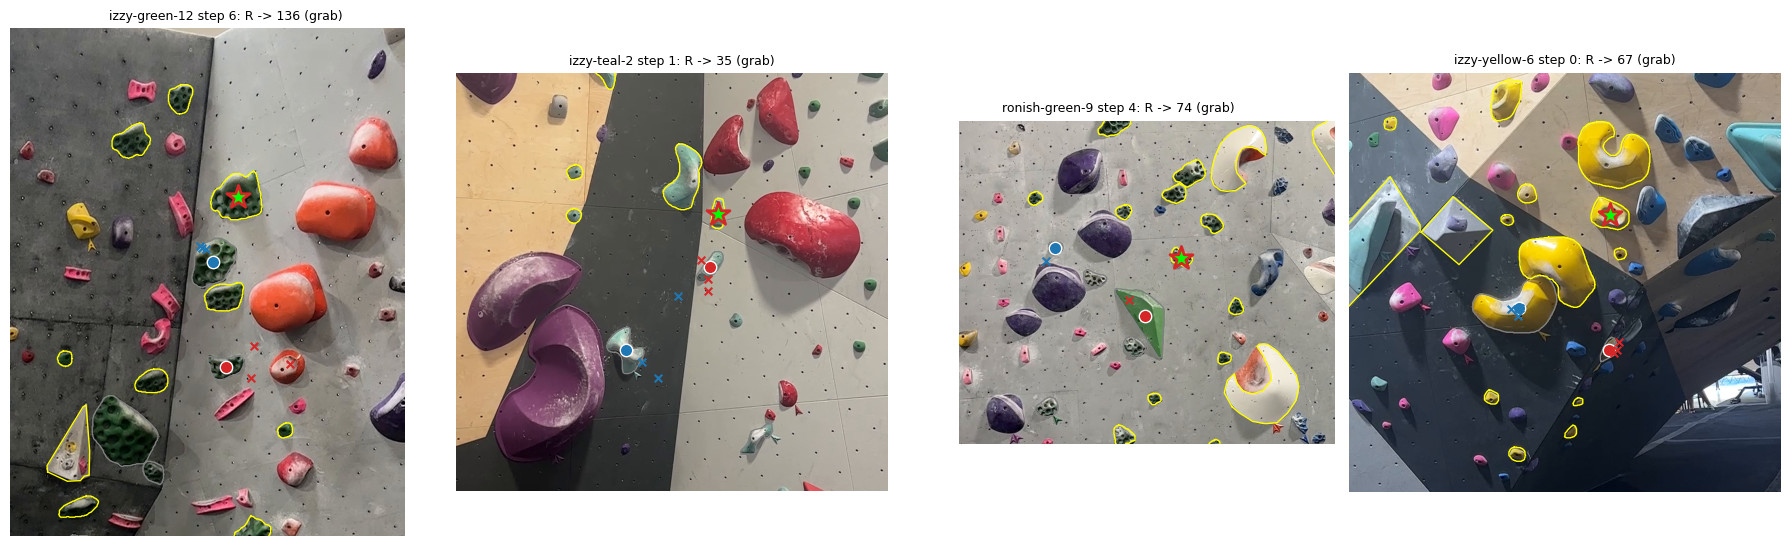

In [ ]:
SHOW = 4
polys = {normalize_pos(p): d for p, d in json.load(open(f'{MAP_DIR}/hold_polygons.json')).items()}
rng = np.random.default_rng(0)
pick = rng.choice(np.flatnonzero(c), size=min(SHOW, c.sum()), replace=False)
fig, axes = plt.subplots(1, len(pick), figsize=(4.5 * len(pick), 8))
for ax, i in zip(np.atleast_1d(axes), pick):
    e = ex.iloc[i]
    img = cv2.imread(f'{MAP_DIR}/{e.position_id}_frame.png')
    ax.imshow(np.zeros((1920, 1080, 3), np.uint8) if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    n = mask[i].sum()
    for j in range(n):
        h = int(hold_ids[i, j])
        for part in polys[e.position_id][str(h)]:
            p = np.array(part)
            ax.plot(*np.vstack([p, p[:1]]).T, color='grey' if X[i, j, 11] else 'yellow', lw=1)
    for hand, col in (('L', 'tab:blue'), ('R', 'tab:red')):
        ax.scatter(e[f'{hand}_x'], e[f'{hand}_y'], s=80, color=col, edgecolor='white', zorder=4)
        jit = ex[(ex.source == e.example_id) & (ex.is_jitter == 1)]
        ax.scatter(jit[f'{hand}_x'], jit[f'{hand}_y'], marker='x', s=30, color=col, zorder=4)
    tc = candidates[(e.route_id, e.position_id)].set_index('hold_id').loc[e.target_hold]
    ax.scatter(tc.cx, tc.cy, marker='*', s=300, color='lime',
               edgecolor='tab:blue' if e.hand == 'L' else 'tab:red', lw=2, zorder=5)
    ys = [e.L_y, e.R_y, tc.cy]
    ax.set_ylim(max(ys) + 250, min(ys) - 250)
    ax.set_xlim(min(e.L_x, e.R_x, tc.cx) - 300, max(e.L_x, e.R_x, tc.cx) + 300)
    ax.set_title(f'{e.video} step {e.step}: {e.hand} -> {e.target_hold} ({e.kind})', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/checks/examples.png', dpi=110, bbox_inches='tight')
plt.show()

## Cell 8: Baselines

- **Nearest hold above the leading hand**: the leading hand is the higher one so predict the closest candidate above it that neither hand is on.
- **Random hold above**: the expected score of picking uniformly among candidates above the leading hand.
- **Hand**: predict that the **lower** hand moves.

In [ ]:
Xc, Mc, Tc, Hc = X[c], mask[c], target[c], target_hand[c]
kind_c = ex.kind.to_numpy()[c]
lead = np.where(Xc[:, 0, 1] - Xc[:, 0, 3] < 0, 0, 1)   # same hold: dy_L < dy_R  <=>  left hand is higher
nearest_ok, rand_exp = [], []
for i in range(len(Xc)):
    n = Mc[i].sum()
    dx, dy = Xc[i, :n, 2 * lead[i]], Xc[i, :n, 2 * lead[i] + 1]
    free = (Xc[i, :n, 6] == 0) & (Xc[i, :n, 7] == 0)
    above = free & (dy > 0)
    pool = above if above.any() else free
    d = np.where(pool, np.hypot(dx, dy), np.inf)
    nearest_ok.append(np.argmin(d) == Tc[i])
    rand_exp.append(above[Tc[i]] / above.sum() if above.any() else 0.0)
nearest_ok, rand_exp = np.array(nearest_ok), np.array(rand_exp)
lower = 1 - lead
print(f'Nearest hold above the leading hand: {nearest_ok.mean():.1%} '
      f'(grabs {nearest_ok[kind_c == "grab"].mean():.1%}, matches {nearest_ok[kind_c == "match"].mean():.1%})')
print(f'Random hold above:                   {rand_exp.mean():.1%}')
print(f'Lower hand moves:                    {(lower == Hc).mean():.1%}')

Nearest hold above the leading hand: 42.4% (grabs 50.9%, matches 1.9%)
Random hold above:                   17.8%
Lower hand moves:                    77.5%
